# A distance-3 surface code on IQM Emerald

**IQM QEC challenge** — Epita-Q · Alexis, Cyril, Robin, Victor

This notebook presents our approach and our results: running a **quantum memory experiment** on IQM's 54-qubit processor **Emerald**. We use a distance-3 **rotated surface code** without mid-circuit reset, decode it, and measure how fast the encoded (logical) qubit loses its information.

Everything uses the project code directly. By default it runs **offline**, from the hardware data we saved in `runs/`. The cells that need the QPU or a long training run are switched off by a flag.

**Plan**

1. The problem: protecting a qubit with the surface code
2. The circuit without reset
3. Placing the code on Emerald with zero SWAPs
4. The hardware data
5. The noise model: calibrated, then characterized
6. What the syndromes revealed: QB26
7. Four decoders on the same shots
8. From error probability to error rate per round
9. Beyond distance 3: threshold and Λ
10. What the GNN learned
11. Summary and next steps

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook uses the project code directly (repo root).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

from decoders import BPOSDDecoder, DefectGNNDecoder, MWPMDecoder, UnionFindDecoder
from emerald_noise import EmeraldNoiseModel
from fit_ler import fit_logical_error_rate
from internal_helpers import get_meas_order, get_qubit_lists
from surface_code import make_stim_circuit

NEW = ROOT / "runs/20261121_193303_main"   # final placement (QB26 excluded), 300 000 shots
OLD = ROOT / "runs/20261121_181236_main"   # first placement (with QB26), 100 000 shots
FIG = ROOT / "runs/figures"                # results of make_figures.py / gnn_ablation.py
ROUNDS = [1, 2, 3, 4, 5]


def stim_to_name(run):
    # stim qubit index -> Emerald qubit name, for one run
    layout = json.loads((run / "layout.json").read_text())
    return {int(k): v for k, v in layout["stim_to_name"].items()}


def load_run(run, rounds):
    data = np.load(run / f"r{rounds}.npz")
    return data["det_events"].astype(bool), data["obs_flips"].astype(bool)


def train_test(n_shots, rounds):
    # Same split as compare_decoders.py: half to train/characterize, half to test.
    perm = np.random.default_rng(rounds).permutation(n_shots)
    return perm[: n_shots // 2], perm[n_shots // 2:]


def dem_of(model, circuit, names, decompose=True):
    # Detector error model of the circuit under a noise model, placed on given qubits
    return model.apply(circuit, names).detector_error_model(
        decompose_errors=decompose, approximate_disjoint_errors=True)


def logical_error(pred, obs):
    return float(np.mean(np.any(pred.reshape(obs.shape) != obs, axis=1)))

## 1. The problem: protecting a qubit with the surface code

A physical qubit loses its state after a few microseconds. The **surface code** spreads one logical qubit over a grid of qubits:

- **data qubits** (9 for $d=3$) hold the information;
- **ancilla qubits** (8) measure the **stabilizers**: parities of 4 (or 2) neighbouring data qubits. The parities are measured, not the data itself.

If an error hits a data qubit, the neighbouring parities change. A **detector** fires when a parity changes between two rounds. The **decoder** reads the pattern of detectors and guesses which correction to apply.

The experiment is a **memory**: prepare $|0\rangle_L$, run $n$ rounds of stabilizer measurements, read the data qubits, and check whether the logical value flipped. That gives $P_L(n)$, and from it the **logical error rate per round** $\varepsilon_L$.

The challenge adds one constraint: **no mid-circuit reset** of the ancillas.

## 2. The circuit without reset

Without reset, an ancilla keeps its previous result. It measures $m_k = s_k \oplus m_{k-1}$, where $s_k$ is the true parity in round $k$. The parity change between rounds $k-1$ and $k$ is then:

$$s_k \oplus s_{k-1} = m_k \oplus m_{k-2}$$

So each detector compares an ancilla's results **two rounds apart**. `make_stim_circuit(distance, rounds, no_reset=True)` removes the ancilla resets and rewrites every detector this way.

**Check**: without noise, every detector must be deterministic, i.e. it never fires.

In [2]:
c = make_stim_circuit(3, 3)
det, obs = c.compile_detector_sampler(seed=0).sample(20_000, separate_observables=True)
pd.Series({
    "qubits used": len(c.get_final_qubit_coordinates()),
    "detectors (3 rounds)": c.num_detectors,
    "resets (data-qubit preparation only)": sum(op.name in ("R", "RX") for op in c.flattened()),
    "detector fire rate without noise": det.mean(),
    "logical flips without noise": obs.mean(),
}).to_frame("value")

,value
qubits used,17.0
detectors (3 rounds),24.0
resets (data-qubit preparation only),1.0
detector fire rate without noise,0.0
logical flips without noise,0.0


**Reading:** without noise no detector ever fires, and the logical value never flips. The resets left in the circuit act on the data qubits only, before the first round. The rewritten detectors are correct.

## 3. Placing the code on Emerald with zero SWAPs

Emerald's qubits form a square grid, and a CZ gate is only possible between neighbours (couplers). The code needs 17 qubits connected exactly like the surface code. If a gate falls between two qubits that aren't coupled, the compiler has to add **SWAPs**, and each SWAP is 3 extra CZs, so 3 extra chances of error.

What we do (`layout_search.py`):

1. We enumerate **every** embedding of the code's graph into Emerald's coupling map (VF2): there are **76**, or **12** once QB26 is excluded.
2. We simulate each placement with the calibrated noise model of the day and keep the one with the lowest $P_L$.
3. We transpile with `routing_method="none"`: if a gate were not on a coupler, the transpile would **fail**. We also check the instructions sent to the QPU.

In [3]:
layout = json.loads((NEW / "layout.json").read_text())
names = stim_to_name(NEW)
print("Excluded:", layout["excluded"], "| simulated P_L of the chosen placement (3 rounds):", layout["simulated_P_L_r3"])
pd.DataFrame({"Emerald qubit": names}).rename_axis("stim qubit").sort_index().T

Excluded: ['QB26'] | simulated P_L of the chosen placement (3 rounds): 0.0422


stim qubit,1,2,3,5,8,9,10,11,12,13,14,15,16,17,18,19,25
Emerald qubit,QB38,QB30,QB29,QB20,QB45,QB37,QB36,QB28,QB27,QB19,QB51,QB50,QB44,QB43,QB35,QB34,QB42


In [4]:
swaps = json.loads((FIG / "swaps.json").read_text())
swaps

{'ideal_cz': 72,
 'rows': {'Naive: QB1..QB17 in order': {'cz': 222,
   'depth': 150,
   'sim_P': None,
   'qubits': None,
   'extra_cz': 150,
   'swaps_equiv': 50.0},
  'Qiskit default layout': {'cz': 72,
   'depth': 25,
   'sim_P': 0.21845,
   'qubits': ['QB1',
    'QB2',
    'QB3',
    'QB4',
    'QB5',
    'QB6',
    'QB9',
    'QB10',
    'QB11',
    'QB12',
    'QB13',
    'QB18',
    'QB19',
    'QB20',
    'QB21',
    'QB26',
    'QB27'],
   'has_QB26': True,
   'extra_cz': 0,
   'swaps_equiv': 0.0},
  'Ours: calibrated + characterized': {'cz': 72,
   'depth': 25,
   'sim_P': 0.17061,
   'qubits': ['QB19',
    'QB20',
    'QB27',
    'QB28',
    'QB29',
    'QB30',
    'QB34',
    'QB35',
    'QB36',
    'QB37',
    'QB38',
    'QB42',
    'QB43',
    'QB44',
    'QB45',
    'QB50',
    'QB51'],
   'has_QB26': False,
   'extra_cz': 0,
   'swaps_equiv': 0.0}}}

**Reading:** a naive mapping (stim qubit $i$ to physical qubit $i$) needs about **50 SWAPs** (222 CZs). Qiskit's default transpiler finds a placement with few SWAPs, but it uses QB26 and simulates at 21.8 %. Our search uses **zero SWAPs**, only the 72 CZs of the code itself, and the best qubits.

👉 Emerald's square grid is exactly the surface code's grid: the gain comes from choosing **which** qubits to use, not from routing.

⚠️ Redoing the search needs the live backend and its calibration. Set `RUN_QPU = True` (token in `TOKEN_IQM` or `~/.iqm_token`).

In [5]:
RUN_QPU = False

if RUN_QPU:
    from iqm.qiskit_iqm import IQMProvider
    from layout_search import find_best_layout
    from run_on_hardware import TOKEN
    backend = IQMProvider("https://cocos.resonance.meetiqm.com/emerald", token=TOKEN).get_backend()
    calibration = EmeraldNoiseModel.from_iqm(TOKEN, "emerald")
    best, ranking = find_best_layout(make_stim_circuit(3, 3), backend, calibration, rounds=3, exclude=["QB26"])
    print(best)

## 4. The hardware data

`main_runs.py` ran the code on Emerald for **1 to 5 rounds**, 60 000 shots each, in jobs of 10 000 shots. It saved the detectors, the logical flips and the raw measurements, plus the calibration at the start and the end.

Without a decoder, $P_L$ is the raw rate at which the logical value flips.

In [6]:
hw = {r: load_run(NEW, r) for r in ROUNDS}
pd.DataFrame({
    r: {"shots": len(d), "detector fire rate": d.mean(), "P_L without decoder": o.mean()}
    for r, (d, o) in hw.items()
}).T.rename_axis("rounds").round(3)

,shots,detector fire rate,P_L without decoder
rounds,,,
1,60000.0,0.051,0.057
2,60000.0,0.154,0.150
3,60000.0,0.198,0.231
4,60000.0,0.218,0.292
5,60000.0,0.233,0.339


**Reading:** detectors fire in 5 % of cases at 1 round and in 23 % at 5 rounds. The raw logical error grows from 6 % (1 round) to 34 % (5 rounds), heading towards 50 % (a coin flip). The decoder has to bring this down.

## 5. The noise model: calibrated, then characterized

To build decoders (and to project to larger codes), we need a **noise model** that reproduces Emerald. `EmeraldNoiseModel` turns IQM's calibration into Stim noise, gate by gate and qubit by qubit:

- **gates**: depolarizing noise computed from the fidelities, $p_{1q} = 1.5\,(1-F)$ and $p_{2q} = 1.25\,(1-F)$;
- **readout**: a flip with probability $1 - F_{\text{readout}}$;
- **idling**: $T_1/T_2$ relaxation during each layer, including the 1.5 µs readout.

The calibration alone is too optimistic. Using the **training half** of the hardware shots, `characterize.py` estimates the probability $p_{ij}$ of every edge of the detector graph (the method from Google 2021). It then fits **one multiplier per qubit** so the model reproduces them.

**Test**: simulate each model, decode with MWPM, and compare to MWPM on the hardware **test half**.

In [7]:
calibrated = EmeraldNoiseModel.load(str(NEW / "noise_model_start.json"))
characterized = EmeraldNoiseModel.load(str(NEW / "noise_model_characterized.json"))


def simulated_mwpm(model, rounds, shots=100_000):
    c = make_stim_circuit(3, rounds)
    det, obs = model.apply(c, names).compile_detector_sampler(seed=rounds).sample(shots, separate_observables=True)
    return logical_error(MWPMDecoder(dem_of(model, c, names)).decode(det), obs)


def hardware_mwpm(rounds):
    det, obs = hw[rounds]
    _, test = train_test(len(det), rounds)
    dem = dem_of(calibrated, make_stim_circuit(3, rounds), names)
    return logical_error(MWPMDecoder(dem).decode(det[test]), obs[test])


models = pd.DataFrame({
    r: {"simulation, calibrated": simulated_mwpm(calibrated, r),
        "simulation, characterized": simulated_mwpm(characterized, r),
        "Emerald": hardware_mwpm(r)}
    for r in ROUNDS
}).T.rename_axis("rounds")
(100 * models).round(1)

,"simulation, calibrated","simulation, characterized",Emerald
rounds,,,
1,0.2,1.2,0.8
2,1.8,8.9,8.2
3,4.3,17.1,16.3
4,6.6,24.0,23.1
5,9.1,29.8,28.2


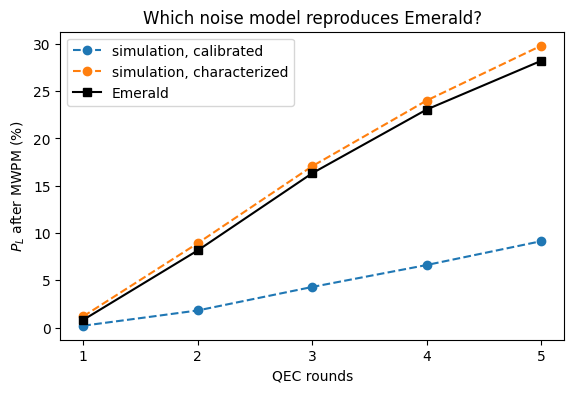

,QB27,QB20,QB36,QB44,QB34,QB37,QB42,QB45,QB28,QB50,QB35,QB29,QB51,QB43,QB19,QB38,QB30
multiplier vs calibration,6.7,5.7,5.6,4.7,4.6,3.5,3.4,2.1,2.1,1.5,1.4,1.1,0.8,0.5,0.5,0.3,0.3


In [8]:
ax = (100 * models).plot(style=["o--", "o--", "ks-"], figsize=(6.5, 4))
ax.set_xticks(ROUNDS)
ax.set_xlabel("QEC rounds")
ax.set_ylabel("$P_L$ after MWPM (%)")
ax.set_title("Which noise model reproduces Emerald?")
plt.show()

pd.Series(characterized.qubit_scale).sort_values(ascending=False).round(1).to_frame("multiplier vs calibration").T

**Reading:**

- The **calibrated** model is far too optimistic: it predicts 3 to 5 times fewer logical errors than Emerald.
- The **characterized** model matches the hardware within 4–9 % (relative) from 2 rounds on, on **test** shots it never saw.
- The multipliers show that the noise isn't uniform: some qubits are 5–7 times worse than calibrated (QB27, QB20, QB36), others are better than calibrated.

👉 Calibration describes each gate in isolation. The syndromes measure the noise of the qubits **in the real circuit** (crosstalk, idling during readout, history). That is what the decoder needs.

## 6. What the syndromes revealed: QB26

On our **first placement**, every decoder did *worse* than no correction at all. To find out why, we look at the detectors of each ancilla, round by round.

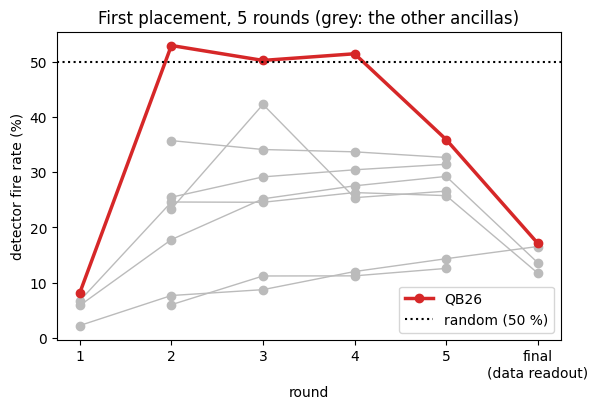

In [9]:
c5 = make_stim_circuit(3, 5)
names_old = stim_to_name(OLD)
position_to_qubit = {tuple(v[:2]): q for q, v in c5.get_final_qubit_coordinates().items()}
det_old, _ = load_run(OLD, 5)

fire = {}
for i, (x, y, t) in c5.get_detector_coordinates().items():
    fire.setdefault(names_old[position_to_qubit[(x, y)]], {})[int(t) + 1] = 100 * det_old[:, i].mean()
fire = pd.DataFrame(fire).sort_index()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(fire.drop(columns="QB26"), "o-", color="#bbbbbb", lw=1)
ax.plot(fire["QB26"], "o-", color="#d62728", lw=2.5, label="QB26")
ax.axhline(50, ls=":", color="k", label="random (50 %)")
ax.set_xticks(range(1, 7), ["1", "2", "3", "4", "5", "final\n(data readout)"])
ax.set_xlabel("round")
ax.set_ylabel("detector fire rate (%)")
ax.set_title("First placement, 5 rounds (grey: the other ancillas)")
ax.legend()
plt.show()

**Reading:** QB26 behaves normally in round 1, then its detector fires **50 % of the time** in rounds 2–4: its measurement is pure noise. (The last point is the final detector, built from the data-qubit readout.) Its readout scrambles its own state, and since nothing resets it, the damage carries into every later round. QB26's calibration showed nothing like this.

The decoder trusts these random detectors and "corrects" errors that don't exist. That's why it was worse than no correction.

Another effect without reset: an ancilla's error depends on the **state it was left in**. We split the shots by the previous outcome:

In [10]:
c3 = make_stim_circuit(3, 3)
position_to_qubit3 = {tuple(v[:2]): q for q, v in c3.get_final_qubit_coordinates().items()}
data3 = np.load(NEW / "r3.npz")
raw, det3 = data3["raw_meas"].astype(bool), data3["det_events"].astype(bool)
order = get_meas_order(c3)               # stim qubit of each measurement, in time order
_, ancillas = get_qubit_lists(c3)

history = {}
for a in ancillas:
    meas = [k for k, q in enumerate(order) if q == a]
    last = [i for i, (x, y, t) in c3.get_detector_coordinates().items()
            if position_to_qubit3[(x, y)] == a and int(t) == 2]
    if len(meas) >= 3 and last:
        previous = raw[:, meas[1]]
        history[names[a]] = {"previous outcome 0": 100 * det3[~previous, last[0]].mean(),
                             "previous outcome 1": 100 * det3[previous, last[0]].mean()}
pd.DataFrame(history).T.round(1).rename_axis("detector fire rate, round 3 (%)")

,previous outcome 0,previous outcome 1
"detector fire rate, round 3 (%)",,
QB30,13.1,47.1
QB37,17.7,26.8
QB28,28.1,37.8
QB19,20.4,41.6
QB51,8.1,22.6
QB44,28.3,38.3
QB35,29.4,40.0
QB42,53.1,53.2


**Reading:** for some ancillas, the rate at which the detector fires depends strongly on the previous result. An ancilla left in $|1\rangle$ relaxes during the long readout, a $T_1$ effect. A fixed-probability noise model can't represent this; a decoder trained on the data can learn it.

QB42 fires about 53 % of the time in every round, whatever its previous outcome: it is random, like QB26. QB42 is an **X**-type ancilla, though, and the Z-basis logical value only depends on the Z ancillas, so in this experiment it costs nothing. An X-basis memory would have to exclude it too.

**The fix**: rerun the placement search **excluding QB26** (12 placements remain) and take new data.

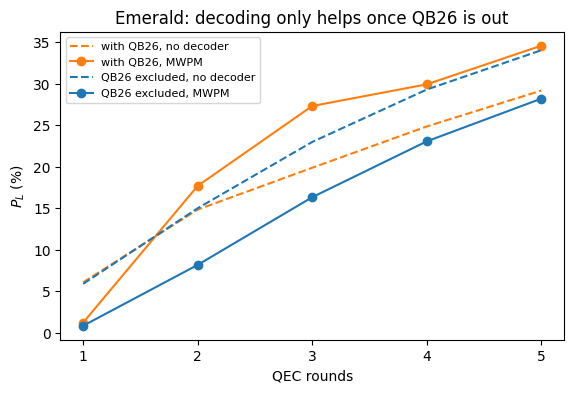

In [11]:
qpu = json.loads((FIG / "qpu.json").read_text())
fig, ax = plt.subplots(figsize=(6.5, 4))
for key, label, color in (("old", "with QB26", "#ff7f0e"), ("new", "QB26 excluded", "#1f77b4")):
    ax.plot(ROUNDS, 100 * np.array(qpu[key]["raw"]), "--", color=color, label=f"{label}, no decoder")
    ax.plot(ROUNDS, 100 * np.array(qpu[key]["mwpm"]), "o-", color=color, label=f"{label}, MWPM")
ax.set_xticks(ROUNDS)
ax.set_xlabel("QEC rounds")
ax.set_ylabel("$P_L$ (%)")
ax.set_title("Emerald: decoding only helps once QB26 is out")
ax.legend(fontsize=8)
plt.show()

**Reading:** with QB26, MWPM is no better than no correction. Without QB26, MWPM goes from 15.0 % to **8.2 %** at 2 rounds.

👉 The biggest improvement in the whole project comes from a **qubit choice**, made from the syndromes, not from a better decoder.

## 7. Four decoders on the same shots

All decoders see the same **test half** of the hardware shots:

- **MWPM** (PyMatching): finds the most likely set of errors as a minimum-weight matching on the detector graph. It is the reference.
- **Union-Find** (our weighted implementation): grows clusters around the detectors that fired. Almost as good, and much faster: the standard for real-time decoding.
- **BP+OSD** (`ldpc`): belief propagation on the full noise model, including correlated X/Z errors, completed by ordered-statistics decoding.
- **GNN** (graph neural network, as in our toric-code project):
  - each detector that fired becomes a node, with features $(x, y, t, \text{type})$;
  - nodes are linked to their $k=6$ nearest neighbours, with weight $1/\text{distance}$;
  - 4 GraphConv layers, then a classifier: "does the logical value flip?";
  - it is pre-trained on simulated shots, then fine-tuned on the **training half** of the hardware shots.

MWPM, Union-Find and BP+OSD use the calibrated noise model as their prior.

⚠️ Union-Find and BP+OSD over all 5 rounds take several minutes, and the GNN takes about 10 minutes per round count. By default we reuse the results saved by `compare_decoders.py`; set `FULL_DECODERS = True` and `RETRAIN_GNN = True` to recompute them.

In [12]:
FULL_DECODERS = False
RETRAIN_GNN = False

saved = json.loads((NEW / "decoders_all.json").read_text())["P_L"]
gnn_saved = {int(k): v for k, v in json.loads((NEW / "gnn_best.json").read_text())["D_all"].items()}

results = {}
for r in ROUNDS:
    det, obs = hw[r]
    train, test = train_test(len(det), r)
    c = make_stim_circuit(3, r)
    dem = dem_of(calibrated, c, names)
    row = {"no decoder": obs[test].mean(),
           "MWPM": logical_error(MWPMDecoder(dem).decode(det[test]), obs[test])}
    if FULL_DECODERS:
        row["Union-Find"] = logical_error(UnionFindDecoder(dem).decode(det[test]), obs[test])
        row["BP+OSD"] = logical_error(BPOSDDecoder(dem_of(calibrated, c, names, decompose=False)).decode(det[test]), obs[test])
    else:
        row["Union-Find"], row["BP+OSD"] = saved[str(r)]["Union-Find"], saved[str(r)]["BP+OSD"]
    if RETRAIN_GNN:
        sim_det, sim_obs = calibrated.scaled(1.7).apply(c, names).compile_detector_sampler(seed=r).sample(
            60_000, separate_observables=True)
        gnn = DefectGNNDecoder(c).fit(sim_det, sim_obs, epochs=12)   # pre-training on simulation
        gnn.fit(det[train], obs[train], epochs=25, lr=5e-4)           # fine-tuning on Emerald
        row["GNN"] = logical_error(gnn.decode(det[test]), obs[test])
    else:
        row["GNN"] = gnn_saved[r]
    results[r] = row

decoders = pd.DataFrame(results).T.rename_axis("rounds")
(100 * decoders).round(1).style.highlight_min(axis=1, subset=["MWPM", "Union-Find", "BP+OSD", "GNN"], color="#c7e9c0")

,no decoder,MWPM,Union-Find,BP+OSD,GNN
rounds,,,,,
1,5.900000,0.800000,1.200000,0.800000,0.800000
2,15.000000,8.200000,8.100000,7.400000,6.800000
3,23.000000,16.300000,15.700000,15.800000,15.500000
4,29.300000,23.100000,22.400000,22.900000,22.700000
5,34.000000,28.200000,27.900000,28.300000,29.100000


**Reading:**

- At **2 rounds**, the GNN is the best decoder: 6.8 %, against 8.2 % for MWPM and 15.0 % without a decoder (**−55 %** of logical errors). Being trained on Emerald's real shots, it learns what the noise model misses, such as the history effects in section 6.
- From **4 rounds**, the four decoders are within one point of each other. Errors accumulate faster than any decoder can correct them, so the limit becomes the **physical noise**, not the decoder.

## 8. From error probability to error rate per round

If each round flips the logical value with probability $\varepsilon_L$, then after $n$ rounds:

$$2P_L(n) = 1 - A\,(1-2\varepsilon_L)^n$$

$A$ absorbs the errors that happen only once: state preparation and the final readout. Without reset, round 1 has no detector two rounds back, so it isn't a full round; the fit uses rounds 2 to 5 (30 000 test shots each).

,eps_L (% / round),± (%),A
no decoder,11.52,0.18,1.18
MWPM,9.80,0.13,1.29
Union-Find,9.51,0.13,1.28
BP+OSD,10.05,0.13,1.34
GNN,10.51,0.13,1.39


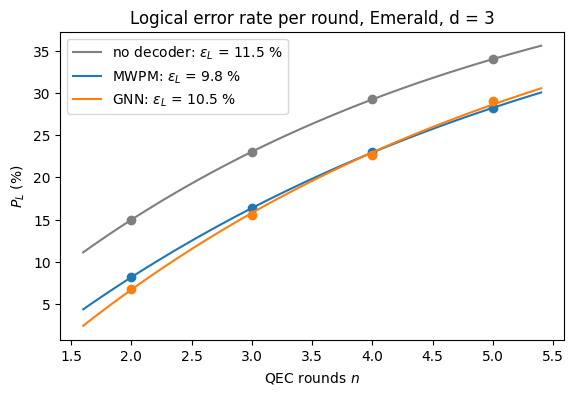

In [13]:
fit_rounds = [2, 3, 4, 5]
fits = {name: fit_logical_error_rate(fit_rounds, decoders.loc[fit_rounds, name], shots=[30_000] * 4, model="offset")
        for name in decoders.columns}
display(pd.DataFrame({name: {"eps_L (% / round)": 100 * f.eps, "± (%)": 100 * f.eps_err, "A": f.A}
                      for name, f in fits.items()}).T.round(2))

n = np.linspace(1.6, 5.4, 50)
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, color in (("no decoder", "#7f7f7f"), ("MWPM", "#1f77b4"), ("GNN", "#ff7f0e")):
    f = fits[name]
    ax.plot(n, 100 * 0.5 * (1 - f.A * (1 - 2 * f.eps) ** n), color=color,
            label=f"{name}: $\\varepsilon_L$ = {100 * f.eps:.1f} %")
    ax.plot(fit_rounds, 100 * decoders.loc[fit_rounds, name], "o", color=color)
ax.set_xlabel("QEC rounds $n$")
ax.set_ylabel("$P_L$ (%)")
ax.set_title("Logical error rate per round, Emerald, d = 3")
ax.legend()
plt.show()

**Reading:** $\varepsilon_L \approx$ **9.5–10.5 % per round** for every decoder, against 11.5 % without one. Decoding lowers the logical error a lot at short depth, but the per-round rate stays close to the raw one. At $d=3$ on Emerald today, the code is **above threshold**: the physical errors are too frequent for the code to gain from more rounds.

That raises the question of larger codes.

## 9. Beyond distance 3: threshold and Λ

Larger codes don't fit on Emerald once the bad qubits are removed. We therefore **project** with the characterized model, which we validated against the hardware at $d=3$:

- each qubit's noise is drawn from the spread measured on Emerald;
- the whole model is multiplied by a factor $f$ (1 = Emerald today);
- for each distance $d$, we simulate $d$ rounds and decode with MWPM.

These simulations take a long time; `make_figures.py` computed and saved them, and here we only plot them.

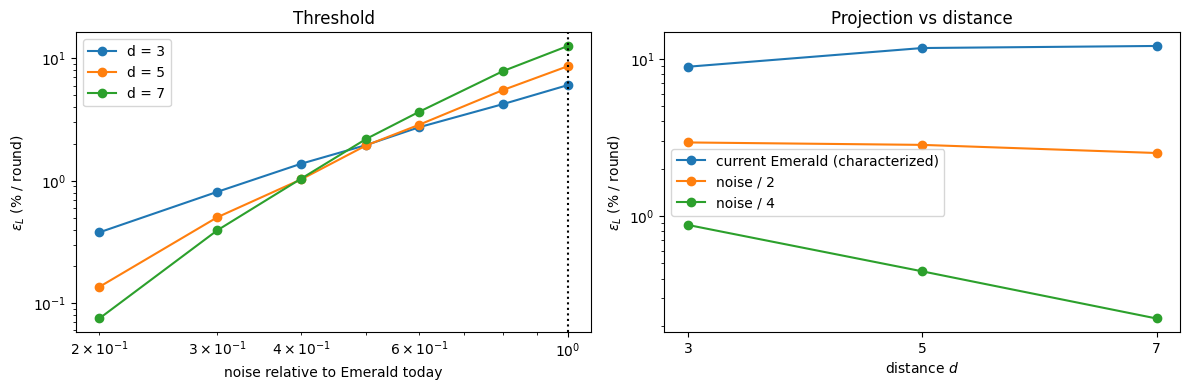

,Λ (3 → 5),Λ (5 → 7)
current Emerald (characterized),0.76,0.97
noise / 2,1.04,1.13
noise / 4,1.97,2.00


In [14]:
threshold = json.loads((FIG / "threshold.json").read_text())
projection = json.loads((NEW / "extrapolation.json").read_text())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for d in ("3", "5", "7"):
    ax1.loglog(threshold["scale"], 100 * np.array(threshold[d]), "o-", label=f"d = {d}")
ax1.axvline(1, ls=":", color="k")
ax1.set_xlabel("noise relative to Emerald today")
ax1.set_ylabel("$\\varepsilon_L$ (% / round)")
ax1.set_title("Threshold")
ax1.legend()
for label, p in projection.items():
    ax2.semilogy([3, 5, 7], [100 * p["eps"][str(d)] for d in (3, 5, 7)], "o-", label=label)
ax2.set_xticks([3, 5, 7])
ax2.set_xlabel("distance $d$")
ax2.set_ylabel("$\\varepsilon_L$ (% / round)")
ax2.set_title("Projection vs distance")
ax2.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({label: {"Λ (3 → 5)": p["eps"]["3"] / p["eps"]["5"], "Λ (5 → 7)": p["eps"]["5"] / p["eps"]["7"]}
              for label, p in projection.items()}).T.round(2)

**Reading:**

- The curves for $d=3, 5, 7$ cross at about **0.45× today's noise**: that is the **threshold**. Above it, a larger code makes things worse; below it, a larger code makes things better.
- $\Lambda = \varepsilon_L(d)/\varepsilon_L(d+2)$ measures the gain from each +2 in distance. Today $\Lambda \approx 0.8$–1, so increasing the distance gains nothing. At a quarter of today's noise, $\Lambda \approx 2$: each step **halves** the logical error, the level Google reported with Willow.

👉 Emerald needs about **2–4 times less noise** for larger surface codes to pay off. Leakage and failures like QB26's aren't in the model, so this is an optimistic bound.

## 10. What the GNN learned: it found the broken qubit

On the first placement (with QB26), the GNN reached 11.5 % at 2 rounds, against about 17.7 % for the classical decoders. Has it learned to ignore QB26?

`gnn_ablation.py` scrambles the detectors of **one ancilla at a time** by shuffling them across shots. This keeps their firing rate but destroys their information. It then counts how many decisions of each decoder change. A decoder that ignores an ancilla barely reacts.

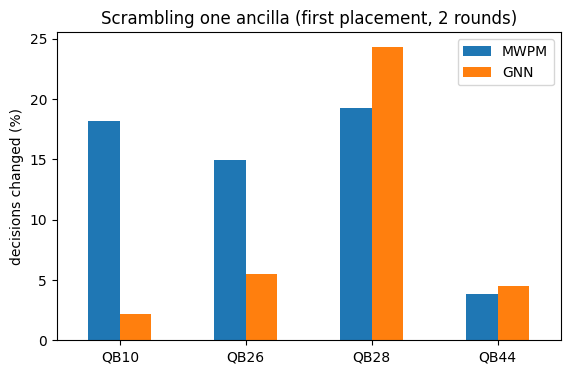

,P_L,"P_L, QB26 scrambled"
MWPM,17.7,17.1
GNN,11.5,12.8


In [15]:
ablation = json.loads((FIG / "ablation.json").read_text())
z_ancillas = {a: v for a, v in ablation["ancillas"].items() if v["MWPM"]["changed"] > 0}   # the ones the Z observable depends on
changed = pd.DataFrame({a: {"MWPM": 100 * v["MWPM"]["changed"], "GNN": 100 * v["GNN"]["changed"]}
                        for a, v in z_ancillas.items()}).T

ax = changed.plot.bar(rot=0, color=["#1f77b4", "#ff7f0e"], figsize=(6.5, 4))
ax.set_ylabel("decisions changed (%)")
ax.set_title("Scrambling one ancilla (first placement, 2 rounds)")
plt.show()

pd.DataFrame({dec: {"P_L": 100 * ablation["P_L"][dec], "P_L, QB26 scrambled": 100 * z_ancillas["QB26"][dec]["P_L"]}
              for dec in ("MWPM", "GNN")}).T.round(1)

**Reading:**

- **MWPM** trusts QB26 like any other ancilla: scrambling it changes 15 % of its decisions, and its $P_L$ even **drops**, because QB26's data was pure noise.
- **The GNN** changes only 5 % of its decisions. From the shots alone, it learned to distrust QB26 and to rely on QB28.

👉 Trained on real data, a GNN finds broken qubits without being told. It does this partly: it also relies less on QB10, which shares data qubits with QB28.

## 11. Summary and next steps

| Step | Result |
|---|---|
| Circuit | no-reset $d=3$ surface code; detectors $m_k \oplus m_{k-2}$, checked without noise |
| Compilation | **zero SWAPs**, checked on the instructions sent (naive mapping: about 50 SWAPs) |
| Hardware | 300 000 shots on Emerald, 1 to 5 rounds |
| Noise model | characterized from the syndromes: matches Emerald within a few %; calibration alone is 3–5× too optimistic |
| Decoders | MWPM, Union-Find, BP+OSD, GNN: **$\varepsilon_L \approx$ 9.5–10.5 % per round**; up to −55 % logical errors (GNN, 2 rounds) |
| Main lever | **excluding QB26**, found from the syndromes, matters more than the choice of decoder |
| Scaling | threshold at about **0.45×** today's noise; $\Lambda \approx 2$ at a quarter of it |

**What limits the logical error rate**, in order:

1. failing qubits that calibration doesn't flag (QB26; QB42 for the X basis);
2. idling and relaxation during the long readout of ancillas that are never reset (history effects);
3. the overall level of physical noise, about 2× above threshold.

**Next steps**:

- characterize at the start of each session and exclude failing qubits automatically;
- a decoder that knows each ancilla's previous result (history-aware), and leakage detection;
- dynamical decoupling on the data qubits during readout;
- the X-basis memory.